# 관통 시나리오 — 하나의 침해를 5계층으로 추적 (통합 실습)

이 노트북은 **한 건의 다단계 침해 사건**을 네트워크 → 웹 로그 → SIEM → ML → LLM 의
다섯 계층에서 **같은 공격자·같은 타임라인**으로 이어서 분석한다. 각 계층의 기법은
본문 챕터에서 독립적으로 다루며, 여기서는 그것들이 하나의 사건에서 어떻게 연결되는지 보여준다.

## 사건 개요
- 공격자: `203.0.113.66` (외부) / 표적: 웹서버 `10.0.0.50`, DB `10.0.0.60`
- 타임라인 (2024-07-05)

| 시각 | 단계 | 계층 | 관련 챕터 |
|---|---|---|---|
| 10:00 | 포트 스캔(정찰) | 네트워크 | ch04·ch05 |
| 10:05 | SQLi 웹 공격 | 웹 로그 | ch12·ch15 |
| 10:10 | SSH 무차별 대입 → 성공 | SIEM 상관 | ch13 |
| 10:20 | C2 비콘(주기 통신) | ML 이상탐지 | ch11 |
| 10:30 | 종합 판단·자동 대응 | LLM | ch17·ch19·ch20 |


In [ ]:
# 파트별 노트북은 같은 종류의 공통 데이터·모델 작업 폴더를 사용합니다.
from pathlib import Path as _BookPath
import os as _book_os
_book_cwd = _BookPath.cwd()
if (_book_cwd.name in {"part1", "part2", "part3", "part4"}
        and _book_cwd.parent.name in {"instructor", "exercises", "solutions"}):
    _book_os.chdir(_book_cwd.parent)


In [1]:
# 첫 사용시에만 주석 해제
# !pip install -q anthropic scikit-learn pandas matplotlib

In [2]:
# --- API 키 로드: 환경변수 → 루트 .env → Colab Secrets → getpass (없으면 mock 자동) ---
import os
if not os.environ.get('ANTHROPIC_API_KEY'):
    from pathlib import Path as _P
    for _d in [_P.cwd(), *_P.cwd().parents]:
        _e = _d / '.env'
        if _e.exists():
            for _l in _e.read_text(encoding='utf-8').splitlines():
                if _l.strip().startswith('ANTHROPIC_API_KEY='):
                    os.environ['ANTHROPIC_API_KEY'] = _l.split('=', 1)[1].strip().strip('"').strip("'")
            break
    if not os.environ.get('ANTHROPIC_API_KEY'):
        try:
            from google.colab import userdata
            os.environ['ANTHROPIC_API_KEY'] = userdata.get('ANTHROPIC_API_KEY')
        except Exception:
            pass

import json, re, time
import numpy as np
import pandas as pd
from datetime import datetime, timedelta
API_KEY = os.environ.get('ANTHROPIC_API_KEY')
USE_REAL = bool(API_KEY) and os.environ.get('BOOK_LLM_MODE', 'auto') != 'mock'
print('LLM 모드:', 'Real API' if USE_REAL else 'Mock')

LLM 모드: Mock


In [3]:
# === 한글 폰트 설정 (matplotlib) ===
# 그래프에서 한글이 깨지면(사각형 □) 아래 설치 명령의 주석을 1회 해제해 실행한 뒤 런타임을 재시작한다.
#   Colab / Ubuntu:  !apt-get install -y fonts-noto-cjk fonts-nanum > /dev/null 2>&1
import os, matplotlib
from matplotlib import font_manager
for _fp in [
    '/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc',
    '/usr/share/fonts/truetype/nanum/NanumGothic.ttf',
    'C:/Windows/Fonts/malgun.ttf', '/System/Library/Fonts/AppleSDGothicNeo.ttc',
]:
    if os.path.exists(_fp):
        try: font_manager.fontManager.addfont(_fp)
        except Exception: pass
_avail = {f.name for f in font_manager.fontManager.ttflist}
for _n in ['Malgun Gothic', 'NanumGothic', 'Noto Sans CJK KR', 'Apple SD Gothic Neo', 'AppleGothic']:
    if _n in _avail:
        matplotlib.rcParams['font.family'] = _n; break
matplotlib.rcParams['axes.unicode_minus'] = False

In [4]:
# --- 공유 엔티티 & 타임라인 (모든 계층이 이 상수를 공유) ---
ATTACKER = '203.0.113.66'
WEB, DB = '10.0.0.50', '10.0.0.60'
BASE = datetime(2024, 7, 5, 10, 0, 0)
rng = np.random.default_rng(42)
incident = []   # 각 계층이 탐지 결과를 여기에 append → 마지막에 타임라인으로
def log_stage(ts, layer, stage, detail, severity):
    incident.append({'ts': ts, 'layer': layer, 'stage': stage, 'detail': detail, 'severity': severity})
print('공격자:', ATTACKER, '| 표적:', WEB)

공격자: 203.0.113.66 | 표적: 10.0.0.50


---
## Step 1. 네트워크 계층 — 포트 스캔 정찰 탐지 (ch04·ch05)

In [5]:
# 공격자가 10:00 에 표적의 여러 포트에 SYN 을 보낸다(정찰). 정상 호스트는 소수 포트만.
scan = pd.DataFrame({
    'src': [ATTACKER]*180 + [f'10.0.0.{i}' for i in rng.integers(2, 40, size=60)],
    'dst': [WEB]*240,
    'dport': list(rng.integers(1, 1024, size=180)) + list(rng.choice([80, 443], size=60)),
    'flag': ['S']*240,
})
# 탐지: 같은 src 가 짧은 시간에 접근한 '고유 목적지 포트 수'
ports_per_src = scan.groupby('src')['dport'].nunique().sort_values(ascending=False)
top_src, top_ports = ports_per_src.index[0], int(ports_per_src.iloc[0])
is_scan = top_ports > 100
print(f'최다 포트 접근 src={top_src}, 고유 포트={top_ports} → 스캔 {"의심" if is_scan else "정상"}')
if is_scan:
    log_stage(BASE, '네트워크', '포트 스캔', f'{top_src} 가 {top_ports}개 포트 접근', 3)

최다 포트 접근 src=203.0.113.66, 고유 포트=165 → 스캔 의심


---
## Step 2. 웹 로그 계층 — SQLi 공격 탐지 (ch12·ch15)

In [6]:
# 10:05 공격자가 로그인 파라미터에 SQLi 를 시도. 정상 요청 사이에 섞여 있다.
normal_uris = ['/index.html', '/search?q=laptop', '/products?cat=tech', '/login', '/api/v1/users/42']
attack_uris = ["/login?id=1' OR 1=1--", "/search?q=' UNION SELECT pw FROM users--"]
weblog = pd.DataFrame({
    'ts':  [BASE + timedelta(minutes=5, seconds=int(s)) for s in rng.integers(0, 120, size=60)],
    'src': list(rng.choice(['10.0.0.23', '10.0.0.31', ATTACKER], size=54)) + [ATTACKER]*6,
    'uri': list(rng.choice(normal_uris, size=54)) + list(rng.choice(attack_uris, size=6)),
})
SQLI = re.compile(r"union\s+select|or\s+1=1|--|'\s*or", re.I)
weblog['sqli'] = weblog['uri'].str.contains(SQLI)
hits = weblog[weblog['sqli']]
print(f'SQLi 의심 요청 {len(hits)}건, 출발지: {sorted(hits["src"].unique())}')
if len(hits):
    t = hits['ts'].min().to_pydatetime()
    log_stage(t, '웹로그', 'SQLi 공격', f'{ATTACKER} 가 로그인/검색에 SQLi {len(hits)}건', 4)

SQLi 의심 요청 6건, 출발지: ['203.0.113.66']


---
## Step 3. SIEM 계층 — 무차별 대입 후 성공 상관 (ch13)

In [7]:
# 10:10 공격자가 SSH 로 다수 실패 후 1회 성공. 방화벽 차단 로그도 함께.
auth = pd.DataFrame({
    'ts':     [BASE + timedelta(minutes=10, seconds=int(i*4)) for i in range(14)],
    'src':    [ATTACKER]*14,
    'result': ['failure']*12 + ['success']*2,
})
fails = (auth['result'] == 'failure').sum()
success_after = ((auth['result'] == 'success') & (auth.index >= 12)).any()
brute_then_success = fails >= 5 and success_after
print(f'SSH 실패 {fails}회 후 성공 → brute-then-success {"경보" if brute_then_success else "없음"}')
if brute_then_success:
    t = auth[auth['result'] == 'success']['ts'].min().to_pydatetime()
    log_stage(t, 'SIEM', 'SSH 무차별대입 성공', f'{ATTACKER} 실패 {fails}회 후 로그인 성공', 5)

SSH 실패 12회 후 성공 → brute-then-success 경보


---
## Step 4. ML 계층 — C2 비콘(주기적 통신) 이상탐지 (ch11)

In [8]:
from sklearn.ensemble import IsolationForest
# 10:20 침투 호스트가 공격자에게 '규칙적인 간격'으로 통신(비콘). 정상 통신은 간격이 불규칙하다.
# 비콘의 핵심 신호는 '간격 자체'가 아니라 '간격의 규칙성' = 변동계수(CV = std/mean)가 매우 낮다.
comm = {}
for i in range(10, 20):                                   # 정상 내부 호스트 10대 (불규칙)
    comm[f'10.0.0.{i}'] = rng.exponential(30, 40)
comm['10.0.0.23'] = rng.normal(60, 1.0, 40)               # 침투 호스트 (규칙적 비콘)

feat = pd.DataFrame([{'host': h, 'iat_mean': a.mean(), 'iat_cv': a.std() / a.mean()}
                     for h, a in comm.items()])
iso = IsolationForest(contamination=0.1, random_state=42).fit(feat[['iat_mean', 'iat_cv']])
feat['anomaly'] = iso.predict(feat[['iat_mean', 'iat_cv']]) == -1
beacon_hosts = feat.loc[feat['anomaly'], 'host'].tolist()
print(feat.round(3).to_string(index=False))
print(f'\n비콘 의심 호스트: {beacon_hosts}')
if '10.0.0.23' in beacon_hosts:
    log_stage(BASE + timedelta(minutes=20), 'ML', 'C2 비콘',
              f'10.0.0.23 규칙적 통신(CV={feat.set_index("host").loc["10.0.0.23","iat_cv"]:.3f})', 4)

     host  iat_mean  iat_cv  anomaly
10.0.0.10    28.035   1.046    False
10.0.0.11    24.348   0.974    False
10.0.0.12    37.302   0.942    False
10.0.0.13    34.745   0.895    False
10.0.0.14    33.901   1.098    False
10.0.0.15    30.852   1.026    False
10.0.0.16    26.982   1.113    False
10.0.0.17    27.998   0.795    False
10.0.0.18    36.022   0.927    False
10.0.0.19    37.082   0.926    False
10.0.0.23    59.948   0.018     True

비콘 의심 호스트: ['10.0.0.23']


---
## Step 5. LLM 계층 — 종합 판단·자동 대응 권고 (ch17·ch19·ch20)

In [9]:
# 앞 4계층의 탐지 결과(incident)를 LLM 에 넘겨 하나의 사건으로 종합 판단시킨다.
consolidated = [{'ts': str(e['ts']), 'layer': e['layer'], 'stage': e['stage'],
                 'detail': e['detail'], 'severity': e['severity']} for e in incident]
prompt = f'''다음은 동일 공격자({ATTACKER})에 대한 4개 보안 계층의 탐지 결과다.
하나의 사건으로 종합해 JSON 으로만 답하라.
{json.dumps(consolidated, ensure_ascii=False)}
형식: {{"incident":"요약","kill_chain":["단계..."],"severity":1-5,"actions":["대응1","대응2"]}}'''

if USE_REAL:
    import anthropic
    cli = anthropic.Anthropic()
    resp = cli.messages.create(model='claude-haiku-4-5', max_tokens=512,
        system='당신은 SOC 사고 대응 분석가다. JSON 으로만 답한다.',
        messages=[{'role': 'user', 'content': prompt}])
    text = next((b.text for b in resp.content if getattr(b, 'type', None) == 'text'), '')
    m = re.search(r'\{.*\}', text, re.DOTALL)
    verdict = json.loads(m.group()) if m else {'raw': text}
else:
    verdict = {'incident': f'{ATTACKER} 의 다단계 웹 침해 (정찰→SQLi→SSH탈취→C2)',
               'kill_chain': ['정찰', '초기침투', '자격증명접근', 'C2'],
               'severity': 5,
               'actions': [f'{ATTACKER} 즉시 차단', f'{WEB} 격리 및 세션 종료', 'DB 접근 감사·비밀번호 회전']}
print(json.dumps(verdict, ensure_ascii=False, indent=2))

{
  "incident": "203.0.113.66 의 다단계 웹 침해 (정찰→SQLi→SSH탈취→C2)",
  "kill_chain": [
    "정찰",
    "초기침투",
    "자격증명접근",
    "C2"
  ],
  "severity": 5,
  "actions": [
    "203.0.113.66 즉시 차단",
    "10.0.0.50 격리 및 세션 종료",
    "DB 접근 감사·비밀번호 회전"
  ]
}


---
## Step 6. 타임라인 — 하나의 사건으로 시각화

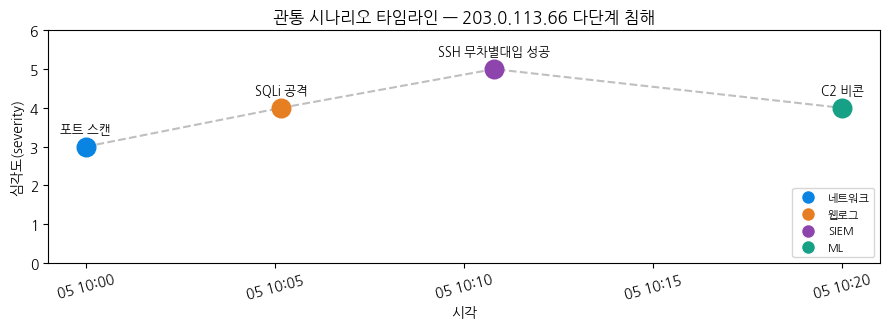

In [10]:
import matplotlib.pyplot as plt
tl = pd.DataFrame(incident).sort_values('ts')
colors = {'네트워크': '#0984e3', '웹로그': '#e67e22', 'SIEM': '#8e44ad', 'ML': '#16a085'}
fig, ax = plt.subplots(figsize=(9, 3.4))
for _, r in tl.iterrows():
    ax.scatter(r['ts'], r['severity'], s=180, color=colors.get(r['layer'], '#e74c3c'), zorder=3)
    ax.annotate(f"{r['stage']}", (r['ts'], r['severity']),
                textcoords='offset points', xytext=(0, 10), ha='center', fontsize=9)
ax.plot(tl['ts'], tl['severity'], '--', color='gray', alpha=0.5, zorder=1)
ax.set_title(f'관통 시나리오 타임라인 — {ATTACKER} 다단계 침해')
ax.set_ylabel('심각도(severity)'); ax.set_ylim(0, 6)
ax.set_xlabel('시각'); plt.xticks(rotation=15)
handles = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=c, markersize=10, label=l)
           for l, c in colors.items()]
ax.legend(handles=handles, loc='lower right', fontsize=8)
plt.tight_layout(); plt.show()

---
## 정리 — 계층별 기법이 하나의 사건으로 연결된다

| 계층 | 이 노트북의 탐지 | 본문 챕터 | 한계·보완 |
|---|---|---|---|
| 네트워크 | 고유 포트 수로 스캔 탐지 | ch04·ch05 | 우회 스캔 → 속도·플래그 분석 |
| 웹 로그 | 정규식 SQLi 시그니처 | ch12·ch15 | 인코딩 우회 → char n-gram 학습 |
| SIEM | 실패→성공 시간창 상관 | ch13 | 룰 정교화 → UEBA |
| ML | 비콘 이상(IsolationForest) | ch11 | 오탐 → 임계·앙상블(ch16) |
| LLM | kill-chain 종합·대응 | ch17·ch19·ch20 | 환각 → RAG·가드(ch17·ch18) |

각 챕터는 독립적으로 학습하되, 실무의 사건은 이렇게 **여러 계층의 신호를 하나로 꿰어야** 보인다.
